In [3]:
import numpy
import pandas
import matplotlib
import sklearn
import platform

print("Python:", platform.python_version())
print("NumPy:", numpy.__version__)
print("Pandas:", pandas.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Scikit-learn:", sklearn.__version__)

Python: 3.14.7
NumPy: 2.5.3
Pandas: 3.0.6
Matplotlib: 3.11.2
Scikit-learn: 1.9.1


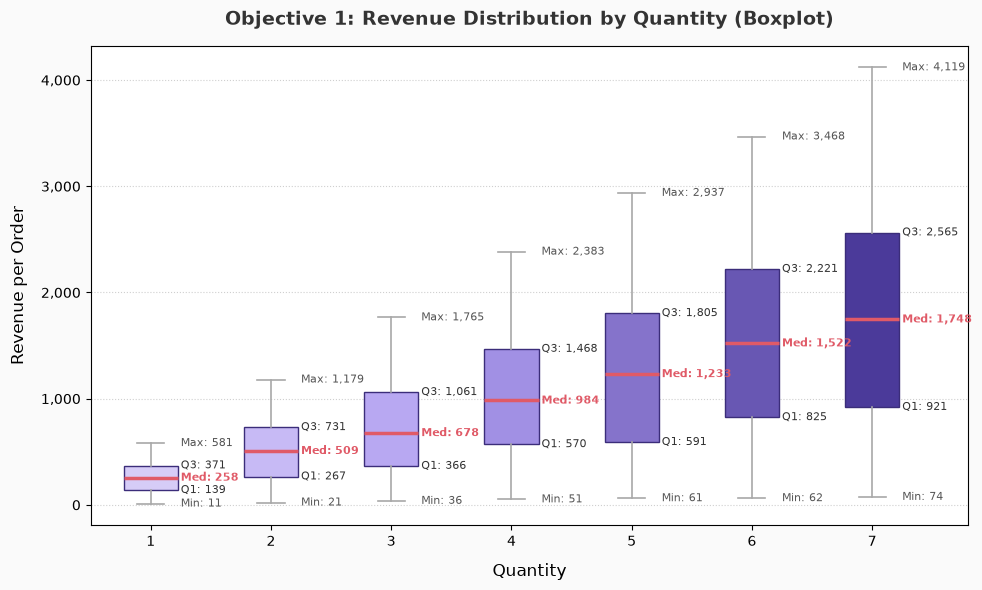

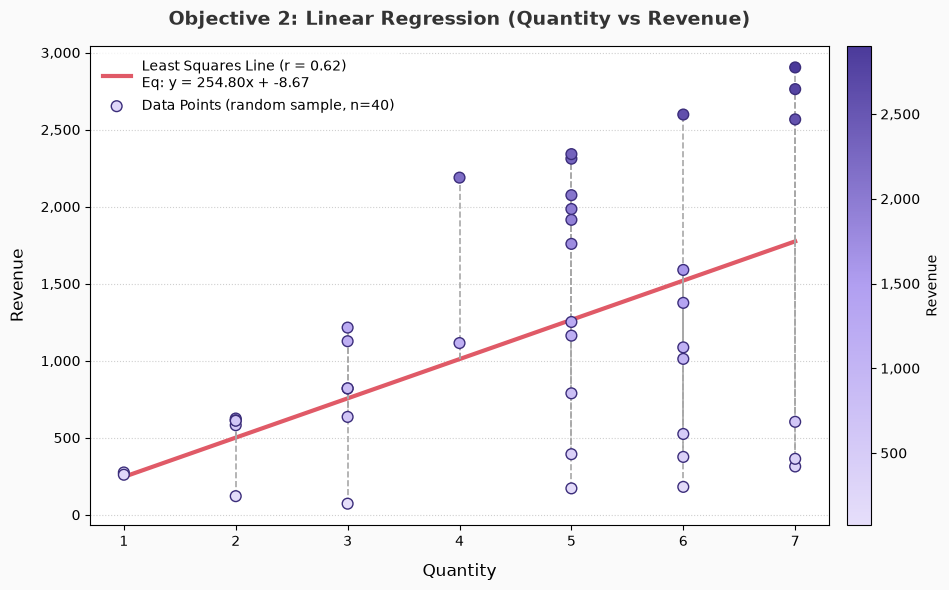


Correlation Matrix:
            Revenue  Quantity  Unit Price  Discount
Revenue       1.000     0.624       0.678    -0.139
Quantity      0.624     1.000       0.001    -0.004
Unit Price    0.678     0.001       1.000     0.013
Discount     -0.139    -0.004       0.013     1.000


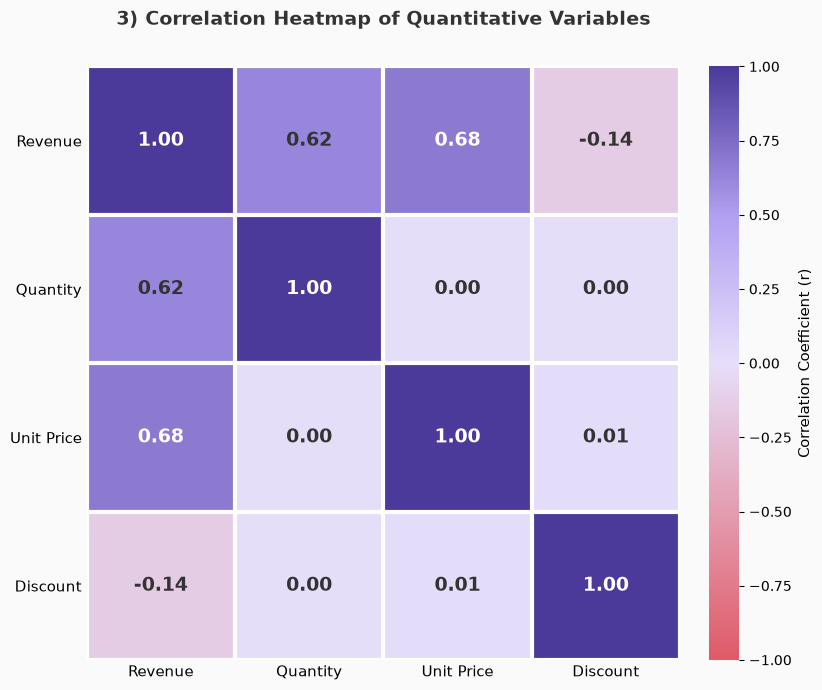


Objective 4: Train/Test Split & Model Evaluation
Train size : 4,000 rows
Test size  : 1,000 rows
R-squared  : 0.8699
RMSE       : 296.09


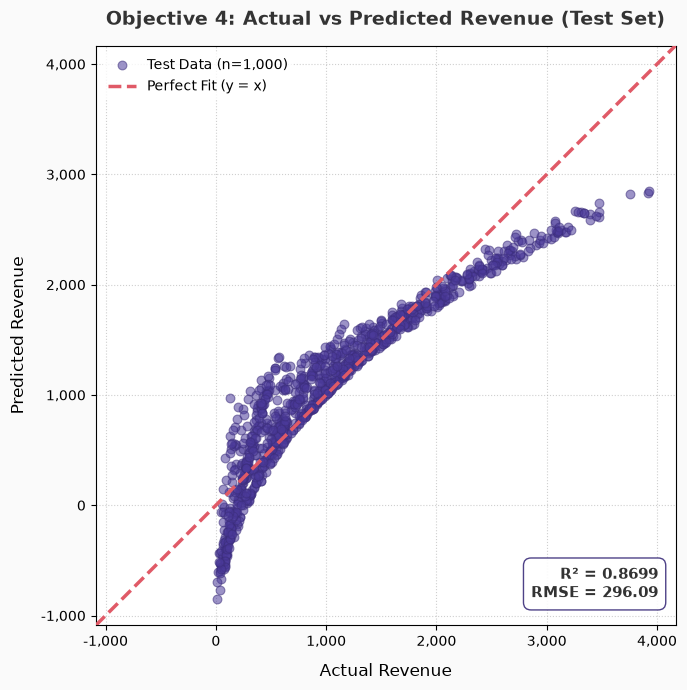


Table 2.5: Linear vs Polynomial Regression (Degree 1-5)
Train size : 4,000 rows | Test size : 1,000 rows
  Degree 1: fitted OK (3 polynomial features)
  Degree 2: fitted OK (9 polynomial features)
  Degree 3: fitted OK (19 polynomial features)
  Degree 4: fitted OK (34 polynomial features)
  Degree 5: fitted OK (55 polynomial features)

Table 2.5: Model Comparison (Linear vs Polynomial Degree 1-5)
 Degree          Model Name Train R² Test R² Train RMSE Test RMSE Train MAE Test MAE
      1   Linear Regression   0.8681  0.8699     300.20    296.09    220.76   219.51
      2 Polynomial Degree 2   0.9982  0.9984      35.30     32.79     23.08    21.33
      3 Polynomial Degree 3   1.0000  1.0000       0.00      0.00      0.00     0.00
      4 Polynomial Degree 4   1.0000  1.0000       0.00      0.00      0.00     0.00
      5 Polynomial Degree 5   1.0000  1.0000       0.00      0.00      0.00     0.00

Lowest Test RMSE : Polynomial Degree 3 (Test RMSE = 0.00, Test R² = 1.0000)

Saved tabl

In [4]:
import os
import matplotlib.pyplot as plt
import matplotlib.ticker
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline                              
from sklearn.preprocessing import PolynomialFeatures, StandardScaler  
from sklearn import metrics

# ---------- กำหนดตำแหน่งไฟล์ ----------
CSV_PATH = r"d:\BUU\python\ecommerce_sales_analytics_5000.csv"
OUT_DIR = os.path.join(os.path.dirname(CSV_PATH), "charts_final_version")
os.makedirs(OUT_DIR, exist_ok=True)

# ---------- สี (ไล่สีม่วงจากอ่อนไปเข้ม) ----------
LIGHT = "#E6DFFA"        # ม่วงอ่อนสุด
DARK = "#4B3A9A"         # ม่วงเข้มสุด
EDGE = "#3B2D7A"         # สีขอบ
LINE = "#E05A67"         # เส้นตรง Least Squares (แดงชมพู)
GREY = "#A8A8A8"
TEXT = "#333333"
BG = "#FAFAFA"

cmap = LinearSegmentedColormap.from_list("light_to_dark_purple", [LIGHT, "#B19FF1", DARK])

def shade(n, lo=0.15, hi=1.0):
    """คืนลิสต์สี n สี ไล่จากอ่อนไปเข้ม"""
    return [cmap(v) for v in np.linspace(lo, hi, n)]

def luminance(col):
    """เช็กความสว่างของสีเพื่อสลับสีฟอนต์ (สำหรับ Heatmap)"""
    return 0.299 * col[0] + 0.587 * col[1] + 0.114 * col[2]

comma = matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}")

def new_figure(title, xlabel, ylabel, figsize=(10, 6), grid=True):
    """ฟังก์ชันสร้าง Template สำหรับกราฟ 1 และ 2"""
    plt.figure(figsize=figsize, facecolor=BG)
    ax = plt.axes()
    ax.set_facecolor("#FFFFFF")
    plt.title(title, fontsize=14, fontweight="bold", color=TEXT, pad=15)
    plt.xlabel(xlabel, fontsize=12, labelpad=10)
    plt.ylabel(ylabel, fontsize=12, labelpad=10)
    if grid:
        plt.grid(axis="y", linestyle=":", alpha=0.6, zorder=1)
    return ax

LABELS = {
    "quantity": "Quantity", 
    "revenue": "Revenue",
    "unit_price": "Unit Price", 
    "discount": "Discount"
}

# ---------- โหลดข้อมูล ----------
df = pd.read_csv(CSV_PATH, encoding="utf-8-sig")[['quantity', 'revenue', 'unit_price', 'discount']]
qs = sorted(df["quantity"].unique())

# =====================================================================
# 1) Boxplot (จากโค้ดเวอร์ชันแรก)
# =====================================================================
data_box = [df.loc[df["quantity"] == q, "revenue"] for q in qs]

ax1 = new_figure("Objective 1: Revenue Distribution by Quantity (Boxplot)", "Quantity", "Revenue per Order")
ax1.yaxis.set_major_formatter(comma)

bp = plt.boxplot(data_box, label=qs, patch_artist=True, widths=0.45,
                 medianprops=dict(color=LINE, linewidth=2.5),
                 whiskerprops=dict(color=GREY, linewidth=1.2),
                 capprops=dict(color=GREY, linewidth=1.2),
                 flierprops=dict(marker="o", markersize=3, markerfacecolor=GREY, markeredgecolor=GREY, alpha=0.5))

for box, col in zip(bp["boxes"], shade(len(qs))):
    box.set(facecolor=col, edgecolor=EDGE, linewidth=1)

for idx, q in enumerate(qs, start=1):
    q_data = df.loc[df["quantity"] == q, "revenue"]
    q1, med, q3 = q_data.quantile(0.25), q_data.median(), q_data.quantile(0.75)
    iqr = q3 - q1
    whis_low = q_data[q_data >= q1 - 1.5 * iqr].min()
    whis_high = q_data[q_data <= q3 + 1.5 * iqr].max()
    offset_x = idx + 0.25  
    
    ax1.text(offset_x, whis_high, f"Max: {whis_high:,.0f}", va="center", fontsize=8, color="#555555")
    ax1.text(offset_x, q3, f"Q3: {q3:,.0f}", va="center", fontsize=8, color=TEXT)
    ax1.text(offset_x, med, f"Med: {med:,.0f}", va="center", fontsize=8, fontweight="bold", color=LINE)
    ax1.text(offset_x, q1, f"Q1: {q1:,.0f}", va="center", fontsize=8, color=TEXT)
    ax1.text(offset_x, whis_low, f"Min: {whis_low:,.0f}", va="center", fontsize=8, color="#555555")

plt.xlim(0.5, len(qs) + 0.8)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "1_boxplot_distribution.png"), dpi=150, facecolor=BG)
plt.show()

# =====================================================================
# 2) Linear Regression (จากโค้ดเวอร์ชันแรก)
# =====================================================================
qmin, qmax = qs[0], qs[-1]
m, c = np.polyfit(df["quantity"], df["revenue"], 1)
r = df["quantity"].corr(df["revenue"])
x_line = np.linspace(qmin, qmax, 100)

sample = df.sample(n=40, random_state=42).sort_values("quantity").reset_index(drop=True)
xs, ys = sample["quantity"].values, sample["revenue"].values
fitted = m * xs + c

ax2 = new_figure("Objective 2: Linear Regression (Quantity vs Revenue)", "Quantity", "Revenue")
ax2.yaxis.set_major_formatter(comma)

plt.plot(x_line, m * x_line + c, color=LINE, linewidth=3,
         label=f"Least Squares Line (r = {r:.2f})\nEq: y = {m:.2f}x + {c:.2f}", zorder=2)

for i in range(len(sample)):
    plt.vlines(xs[i], min(ys[i], fitted[i]), max(ys[i], fitted[i]),
               colors=GREY, linestyles="--", linewidth=1.2, zorder=3)

sc = plt.scatter(xs, ys, c=ys, cmap=cmap, s=60, edgecolors=EDGE, linewidths=1,
                 zorder=4, label="Data Points (random sample, n=40)")

plt.colorbar(sc, label="Revenue", format=comma, pad=0.02)
plt.xticks(qs)
plt.legend(frameon=True, facecolor="#FFFFFF", edgecolor="none", loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "2_linear_regression.png"), dpi=150, facecolor=BG)
plt.show()

# =====================================================================
# 3) Correlation Coefficient + Heatmap (ตามที่คุณส่งมาใหม่)
# =====================================================================
hm_cols = ["revenue", "quantity", "unit_price", "discount"]
corr = df[hm_cols].corr()
corr.index = corr.columns = [LABELS[c] for c in hm_cols]

print("\nCorrelation Matrix:")
print(corr.round(3))
corr.round(4).to_csv(os.path.join(OUT_DIR, "3_correlation_matrix.csv"), encoding="utf-8-sig")

# ลบ = แดงชมพู (LINE), 0 = ม่วงอ่อนสุด (LIGHT), บวกมาก = ม่วงเข้ม (DARK)
heat_cmap = LinearSegmentedColormap.from_list(
    "line_light_dark", [(0.0, LINE), (0.5, LIGHT), (0.75, "#B19FF1"), (1.0, DARK)])

n = len(hm_cols)
fig3, ax3 = plt.subplots(figsize=(8.5, 7), facecolor=BG)
im = ax3.imshow(corr.values, cmap=heat_cmap, vmin=-1, vmax=1)
ax3.set_xticks(range(n))
ax3.set_yticks(range(n))
ax3.set_xticklabels(corr.columns, fontsize=11)
ax3.set_yticklabels(corr.index, fontsize=11)

for i in range(n):
    for j in range(n):
        v = corr.iat[i, j]
        col = heat_cmap((v + 1) / 2)
        label = f"{v:.2f}" if round(v, 2) != 0 else "0.00"
        ax3.text(j, i, label, ha="center", va="center", fontsize=14, fontweight="bold",
                 color="white" if luminance(col) < 0.55 else TEXT)

ax3.set_xticks(np.arange(-0.5, n, 1), minor=True)  # เส้นคั่นช่องสีขาว
ax3.set_yticks(np.arange(-0.5, n, 1), minor=True)
ax3.grid(which="minor", color="white", linewidth=3)
ax3.tick_params(which="both", length=0)

for sp in ax3.spines.values():
    sp.set_visible(False)

cbar = fig3.colorbar(im, ax=ax3, fraction=0.046, pad=0.04)
cbar.set_label("Correlation Coefficient (r)", fontsize=11)
cbar.outline.set_visible(False)
ax3.set_title("3) Correlation Heatmap of Quantitative Variables", fontsize=14, fontweight="bold", color=TEXT, pad=30)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "3_correlation_heatmap.png"), dpi=150, facecolor=BG)
plt.show()

# =====================================================================
# 4) Train/Test Split & Model Evaluation
# =====================================================================
X = df[['quantity', 'unit_price', 'discount']]
y = df['revenue']

# แบ่งข้อมูล Train 80% / Test 20%
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# เทรนโมเดลและทำนายบน Test Set
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# ประเมินผลโมเดล
r2 = metrics.r2_score(y_test, y_pred)
rmse = np.sqrt(metrics.mean_squared_error(y_test, y_pred))

print("\n" + "=" * 50)
print("Objective 4: Train/Test Split & Model Evaluation")
print("=" * 50)
print(f"Train size : {len(X_train):,} rows")
print(f"Test size  : {len(X_test):,} rows")
print(f"R-squared  : {r2:.4f}")
print(f"RMSE       : {rmse:,.2f}")

# ---------- กราฟ Actual vs Predicted ----------
ax4 = new_figure("Objective 4: Actual vs Predicted Revenue (Test Set)",
                 "Actual Revenue", "Predicted Revenue", figsize=(8, 7))
ax4.xaxis.set_major_formatter(comma)
ax4.yaxis.set_major_formatter(comma)
ax4.grid(axis="x", linestyle=":", alpha=0.6, zorder=1)  # เพิ่มกริดแนวตั้งให้อ่านค่าง่ายขึ้น

# กำหนดช่วงแกนให้เท่ากันทั้งสองแกน เพื่อให้เส้น y = x เป็นเส้นทแยงมุมจริง
lim_min = min(y_test.min(), y_pred.min())
lim_max = max(y_test.max(), y_pred.max())
pad = (lim_max - lim_min) * 0.05
lims = (lim_min - pad, lim_max + pad)

plt.scatter(y_test, y_pred, color=DARK, edgecolors=EDGE, linewidths=0.8,
            alpha=0.55, s=40, zorder=3, label=f"Test Data (n={len(y_test):,})")
plt.plot(lims, lims, color=LINE, linestyle="--", linewidth=2.5, zorder=4,
         label="Perfect Fit (y = x)")

plt.xlim(lims)
plt.ylim(lims)
ax4.set_aspect("equal", adjustable="box")

# กล่องแสดงค่า metrics บนกราฟ
ax4.text(0.97, 0.04, f"R² = {r2:.4f}\nRMSE = {rmse:,.2f}",
         transform=ax4.transAxes, ha="right", va="bottom",
         fontsize=11, fontweight="bold", color=TEXT,
         bbox=dict(boxstyle="round,pad=0.5", facecolor="#FFFFFF",
                   edgecolor=EDGE, alpha=0.9))

plt.legend(frameon=True, facecolor="#FFFFFF", edgecolor="none", loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "4_train_test_prediction.png"), dpi=150, facecolor=BG)
plt.show()

# =====================================================================
# 5) [เพิ่มใหม่] เปรียบเทียบ Linear Regression และ Polynomial Regression
#    Degree 1 - 5 (ตารางที่ 2.5)
# =====================================================================
# ใช้ X_train / X_test / y_train / y_test ชุดเดียวกับหัวข้อ 4
# (train_test_split(test_size=0.2, random_state=42)) ทุกโมเดลจึงเปรียบเทียบกันได้อย่างยุติธรรม

MAX_DEGREE = 5

def build_pipeline(degree):
    """สร้าง Pipeline: Scale -> Polynomial Features -> Scale -> Linear Regression
    - StandardScaler และ PolynomialFeatures ถูก fit จาก Training Set เท่านั้น
      (ตอน pipe.fit) แล้วนำไป transform Test Set จึงไม่เกิดข้อมูลรั่วไหล
    - StandardScaler ช่วยลดปัญหาตัวเลขใหญ่เกินไปเมื่อยกกำลังสูง (เช่น unit_price^5)
      ซึ่งไม่เปลี่ยนความสามารถของโมเดล แต่ทำให้การคำนวณเสถียรขึ้น
    """
    return Pipeline([
        ("scale_in", StandardScaler()),
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("scale_poly", StandardScaler()),
        ("reg", LinearRegression()),
    ])

def evaluate(y_true, y_hat):
    """คืนค่า (R², RMSE, MAE)"""
    return (
        metrics.r2_score(y_true, y_hat),
        np.sqrt(metrics.mean_squared_error(y_true, y_hat)),
        metrics.mean_absolute_error(y_true, y_hat),
    )

print("\n" + "=" * 70)
print("Table 2.5: Linear vs Polynomial Regression (Degree 1-5)")
print("=" * 70)
print(f"Train size : {len(X_train):,} rows | Test size : {len(X_test):,} rows")

rows = []
for degree in range(1, MAX_DEGREE + 1):
    pipe = build_pipeline(degree)
    pipe.fit(X_train, y_train)                      # เรียนรู้จาก Training Set เท่านั้น

    tr_r2, tr_rmse, tr_mae = evaluate(y_train, pipe.predict(X_train))
    te_r2, te_rmse, te_mae = evaluate(y_test, pipe.predict(X_test))

    # ตรวจสอบว่าไม่มีค่า NaN / Inf จากการคำนวณ
    if not np.all(np.isfinite([tr_r2, te_r2, tr_rmse, te_rmse, tr_mae, te_mae])):
        raise ValueError(f"Degree {degree}: พบค่า NaN/Inf ในผลการคำนวณ")

    n_feat = pipe.named_steps["poly"].n_output_features_
    print(f"  Degree {degree}: fitted OK ({n_feat} polynomial features)")

    rows.append({
        "Degree": degree,
        "Model Name": "Linear Regression" if degree == 1 else f"Polynomial Degree {degree}",
        "Train R²": tr_r2,
        "Test R²": te_r2,
        "Train RMSE": tr_rmse,
        "Test RMSE": te_rmse,
        "Train MAE": tr_mae,
        "Test MAE": te_mae,
    })

results = pd.DataFrame(rows)

# ---------- แสดงตารางบนหน้าจอ (R² ทศนิยม 4 ตำแหน่ง / RMSE, MAE ทศนิยม 2 ตำแหน่ง) ----------
fmt_r2 = lambda v: f"{v:.4f}"
fmt_err = lambda v: f"{v:,.2f}"
print("\nTable 2.5: Model Comparison (Linear vs Polynomial Degree 1-5)")
print(results.to_string(
    index=False,
    formatters={
        "Train R²": fmt_r2, "Test R²": fmt_r2,
        "Train RMSE": fmt_err, "Test RMSE": fmt_err,
        "Train MAE": fmt_err, "Test MAE": fmt_err,
    }
))

# สรุปโมเดลที่ Test RMSE ต่ำสุด
best = results.loc[results["Test RMSE"].idxmin()]
print(f"\nLowest Test RMSE : {best['Model Name']} "
      f"(Test RMSE = {best['Test RMSE']:,.2f}, Test R² = {best['Test R²']:.4f})")

# ---------- บันทึกเป็น CSV ----------
results_out = results.copy()
for col in ["Train R²", "Test R²"]:
    results_out[col] = results_out[col].map(lambda v: f"{v:.4f}")   # R² = 4 ตำแหน่ง
for col in ["Train RMSE", "Test RMSE", "Train MAE", "Test MAE"]:
    results_out[col] = results_out[col].map(lambda v: f"{v:.2f}")   # RMSE/MAE = 2 ตำแหน่ง

csv_out = os.path.join(OUT_DIR, "5_polynomial_regression_comparison.csv")
results_out.to_csv(csv_out, index=False, encoding="utf-8-sig")
print(f"\nSaved table -> {csv_out}")